# HiDTW 3D Cell Reconstruction — Tutorial (Tile046)

This tutorial walks you through the **HiDTW** pipeline on the 10-layer demo region
**Tile046** included with this repository (`demo_data/`). For the manual demo,
run sections **1–8 → 10b → 11–12**. For Bayesian optimisation, run
**1–10 → 11–12** instead. The tutorial covers:

1. Loaded ten Z slices of 2D cell features (centroids, contours, neighbours).
2. Visualised the raw cell layout and cross-layer correspondence by inspection.
3. Calibrated dataset-specific normalisation divisors used by the matcher.
4. Run a single reconstruction pass with **manual** matching weights.
5. Inspected reconstruction outputs.
6. Optionally run a short **Bayesian optimisation** (n_calls=8) over the four matching
   hyper-parameters (RM, DTW, OT, CENT) and applied the best settings.
7. Aggregated per-track UMI expression from `expression-T046-S*.csv` into a single
   `Tile046.csv.gz` (cells × genes) plus a parallel `Tile046_meta.csv`.

## Requisites

| Dependency | Notes |
|---|---|
| Python >= 3.10 | tested on 3.10 |
| **CUDA-capable GPU** | required by `hidtw_pipeline.cell_reconstruction_runGPU_3Drevised_v10`; aborts on CPU |
| `torch >= 2.0` (with CUDA) | for Soft-DTW and Sinkhorn OT |
| `soft_dtw_cuda` | importable from `PYTHONPATH` (Maghoumi/pytorch-softdtw-cuda) |
| `numba`, `tqdm`, `pandas`, `scipy`, `matplotlib`, `scikit-optimize` | standard stack |


## 1. Setup

Imports, matplotlib defaults, working directory, and GPU probe. Figures are
shown **inline** while PDFs are exported to `tutorial_outputs/Tile046/`.

The reconstruction script discovers data folders with `glob.glob("Tile*")` from
the current working directory, so we `chdir` into the workspace root and create
a symlink `Tile046 -> demo_data/Tile046` if it is not already there.


In [1]:
%matplotlib inline
from __future__ import annotations

import json
import os
import shutil
import subprocess
import sys
import time
import warnings
from pathlib import Path
from typing import Dict, List, Tuple

import numpy as np
import pandas as pd

import matplotlib
matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42
matplotlib.rcParams["svg.fonttype"] = "none"
matplotlib.rcParams["font.family"] = "sans-serif"
matplotlib.rcParams["font.sans-serif"] = ["Helvetica", "Arial", "DejaVu Sans"]
matplotlib.rcParams["figure.dpi"] = 300
matplotlib.rcParams["savefig.bbox"] = "tight"
matplotlib.rcParams["savefig.pad_inches"] = 0.03
matplotlib.rcParams["axes.spines.top"] = False
matplotlib.rcParams["axes.spines.right"] = False
matplotlib.rcParams["axes.linewidth"] = 0.8
matplotlib.rcParams["xtick.direction"] = "out"
matplotlib.rcParams["ytick.direction"] = "out"

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401  (registers 3d projection)

# Okabe-Ito + Paul Tol palette
PALETTE = {
    "primary":   "#332288",  # HiDTW signature
    "secondary": "#4477AA",
    "accent":    "#EE6677",
    "ok_blue":   "#0072B2",
    "ok_orange": "#E69F00",
    "ok_green":  "#009E73",
    "ok_pink":   "#CC79A7",
    "ok_yellow": "#F0E442",
    "neutral":   "#999999",
}

print("matplotlib", matplotlib.__version__)
print("numpy     ", np.__version__)
print("pandas    ", pd.__version__)

matplotlib 3.9.0
numpy      1.26.4
pandas     3.0.3


In [2]:
WORK_DIR = Path.cwd()
PIPELINE_DIR = WORK_DIR / "hidtw_pipeline"
assert (PIPELINE_DIR / "cell_reconstruction_runGPU_3Drevised_v10.py").exists(), (
    f"hidtw_pipeline package not found under {WORK_DIR}; "
    "open this notebook from the HiDTW-3DVCM/ workspace root."
)

DEMO_DATA_DIR = WORK_DIR / "demo_data" / "Tile046"
DEMO_EXPR_DIR = WORK_DIR / "demo_data" / "046"
TILE_NAME = "Tile046"
TILE_PREFIX = "046"
OUT_DIR = WORK_DIR / "tutorial_outputs" / TILE_NAME
OUT_DIR.mkdir(parents=True, exist_ok=True)

os.chdir(WORK_DIR)
sys.path.insert(0, str(WORK_DIR))

import hidtw_pipeline as th

# Expose Tile046/ at cwd so that the matcher's `glob.glob("Tile*")` finds it.
TILE_LINK = WORK_DIR / TILE_NAME
if not TILE_LINK.exists():
    try:
        TILE_LINK.symlink_to(DEMO_DATA_DIR, target_is_directory=True)
        print(f"created symlink: {TILE_LINK} -> {DEMO_DATA_DIR}")
    except OSError as exc:
        shutil.copytree(DEMO_DATA_DIR, TILE_LINK)
        print(f"copied {DEMO_DATA_DIR} -> {TILE_LINK} (symlink unavailable: {exc})")
else:
    print(f"reusing existing path: {TILE_LINK}")

print(f"WORK_DIR   = {WORK_DIR}")
print(f"DEMO_DATA  = {DEMO_DATA_DIR}")
print(f"DEMO_EXPR  = {DEMO_EXPR_DIR}")
print(f"OUT_DIR    = {OUT_DIR}")


created symlink: /root/autodl-tmp/HiDTW-3DVCM/Tile046 -> /root/autodl-tmp/HiDTW-3DVCM/demo_data/Tile046
WORK_DIR   = /root/autodl-tmp/HiDTW-3DVCM
DEMO_DATA  = /root/autodl-tmp/HiDTW-3DVCM/demo_data/Tile046
DEMO_EXPR  = /root/autodl-tmp/HiDTW-3DVCM/demo_data/046
OUT_DIR    = /root/autodl-tmp/HiDTW-3DVCM/tutorial_outputs/Tile046


In [3]:
try:
    import torch
    GPU_AVAILABLE = torch.cuda.is_available()
    if GPU_AVAILABLE:
        print(f"torch  {torch.__version__}  CUDA={torch.version.cuda}  device={torch.cuda.get_device_name(0)}")
    else:
        print(f"torch {torch.__version__}: CUDA NOT AVAILABLE")
        warnings.warn(
            "Sections 6, 9, and 10 require a GPU. You can still run sections "
            "2-4 (loading and visualisation), 5 (calibration is CPU-friendly), "
            "and 11+ if you load pre-computed tracks."
        )
except ImportError as exc:
    GPU_AVAILABLE = False
    print(f"torch import failed: {exc}\nGPU sections will be skipped.")


torch  2.3.0+cu121  CUDA=12.1  device=NVIDIA GeForce RTX 4090


## 2. Load 10-layer cell features

Each `046_S{NN}_features.csv` contains one row per 2D segmented cell. Important
columns:

| column | meaning |
|---|---|
| `cell_id` | unique 2D-cell id (e.g. `T046S01_0001`) |
| `cell_label` | within-slice integer label |
| `slice`, `z` | slice index 1..10 |
| `centroid_x`, `centroid_y` | global pixel coordinates |
| `area`, `aspect_ratio` | shape stats |
| `x_0..x_399`, `y_0..y_399` | 400-point cell contour |
| `adjacent_cells`, `num_adjacent_cells` | semicolon-joined neighbour ids |

The helper [`load_cells_from_csv_files`](hidtw_pipeline/cell_reconstruction_runGPU_3Drevised_v10.py)
materialises a `Cell` dataclass per row and **pre-resamples each contour to 200
points** for the Soft-DTW / OT comparators.

In [4]:
from hidtw_pipeline import cell_reconstruction_runGPU_3Drevised_v10 as cr

cells_by_slice = cr.load_cells_from_csv_files(TILE_NAME)
print(f"Total slices loaded: {len(cells_by_slice)}")


Loading from Tile046: found 10 CSV files

Starting to load 10 CSV files


Loading CSV files: 100%|██████████| 10/10 [00:19<00:00,  1.91s/it]


Cell distribution by slice:
  Slice 1: 554 cells
  Slice 2: 728 cells
  Slice 3: 711 cells
  Slice 4: 620 cells
  Slice 5: 618 cells
  Slice 6: 716 cells
  Slice 7: 781 cells
  Slice 8: 756 cells
  Slice 9: 755 cells
  Slice 10: 785 cells

Total cells loaded: 7024
Total slices loaded: 10


In [5]:
slice_summary = th.slice_summary_table(cells_by_slice)
slice_summary.to_csv(OUT_DIR / "slice_summary.csv", index=False)
slice_summary

,slice,n_cells,area_med,area_q25,area_q75,aspect_med
0,1,554,4566.25,3290.375,5942.500,1.584138
1,2,728,4217.50,2902.750,5666.875,1.690873
2,3,711,4230.00,2982.000,5649.250,1.643617
3,4,620,4776.50,3670.500,6353.125,1.605494
4,5,618,4890.25,3693.750,6260.000,1.619833
5,6,716,4502.25,3097.000,5823.125,1.609291
6,7,781,4194.00,2626.000,5766.500,1.655368
7,8,756,4428.50,3088.375,6007.125,1.623182
8,9,755,4517.50,3015.250,6266.500,1.623892
9,10,785,4056.00,2775.000,5566.000,1.658266


## 3. Visualise raw cells per slice

A 2x5 panel showing all 2D cells in each Z slice. Centroids appear as small
dots; for visual texture we overlay the contour outline of every 30th cell.
The per-slice colour comes from a sequential viridis ramp keyed by `z`, so
later figures will reuse the same palette across panels.

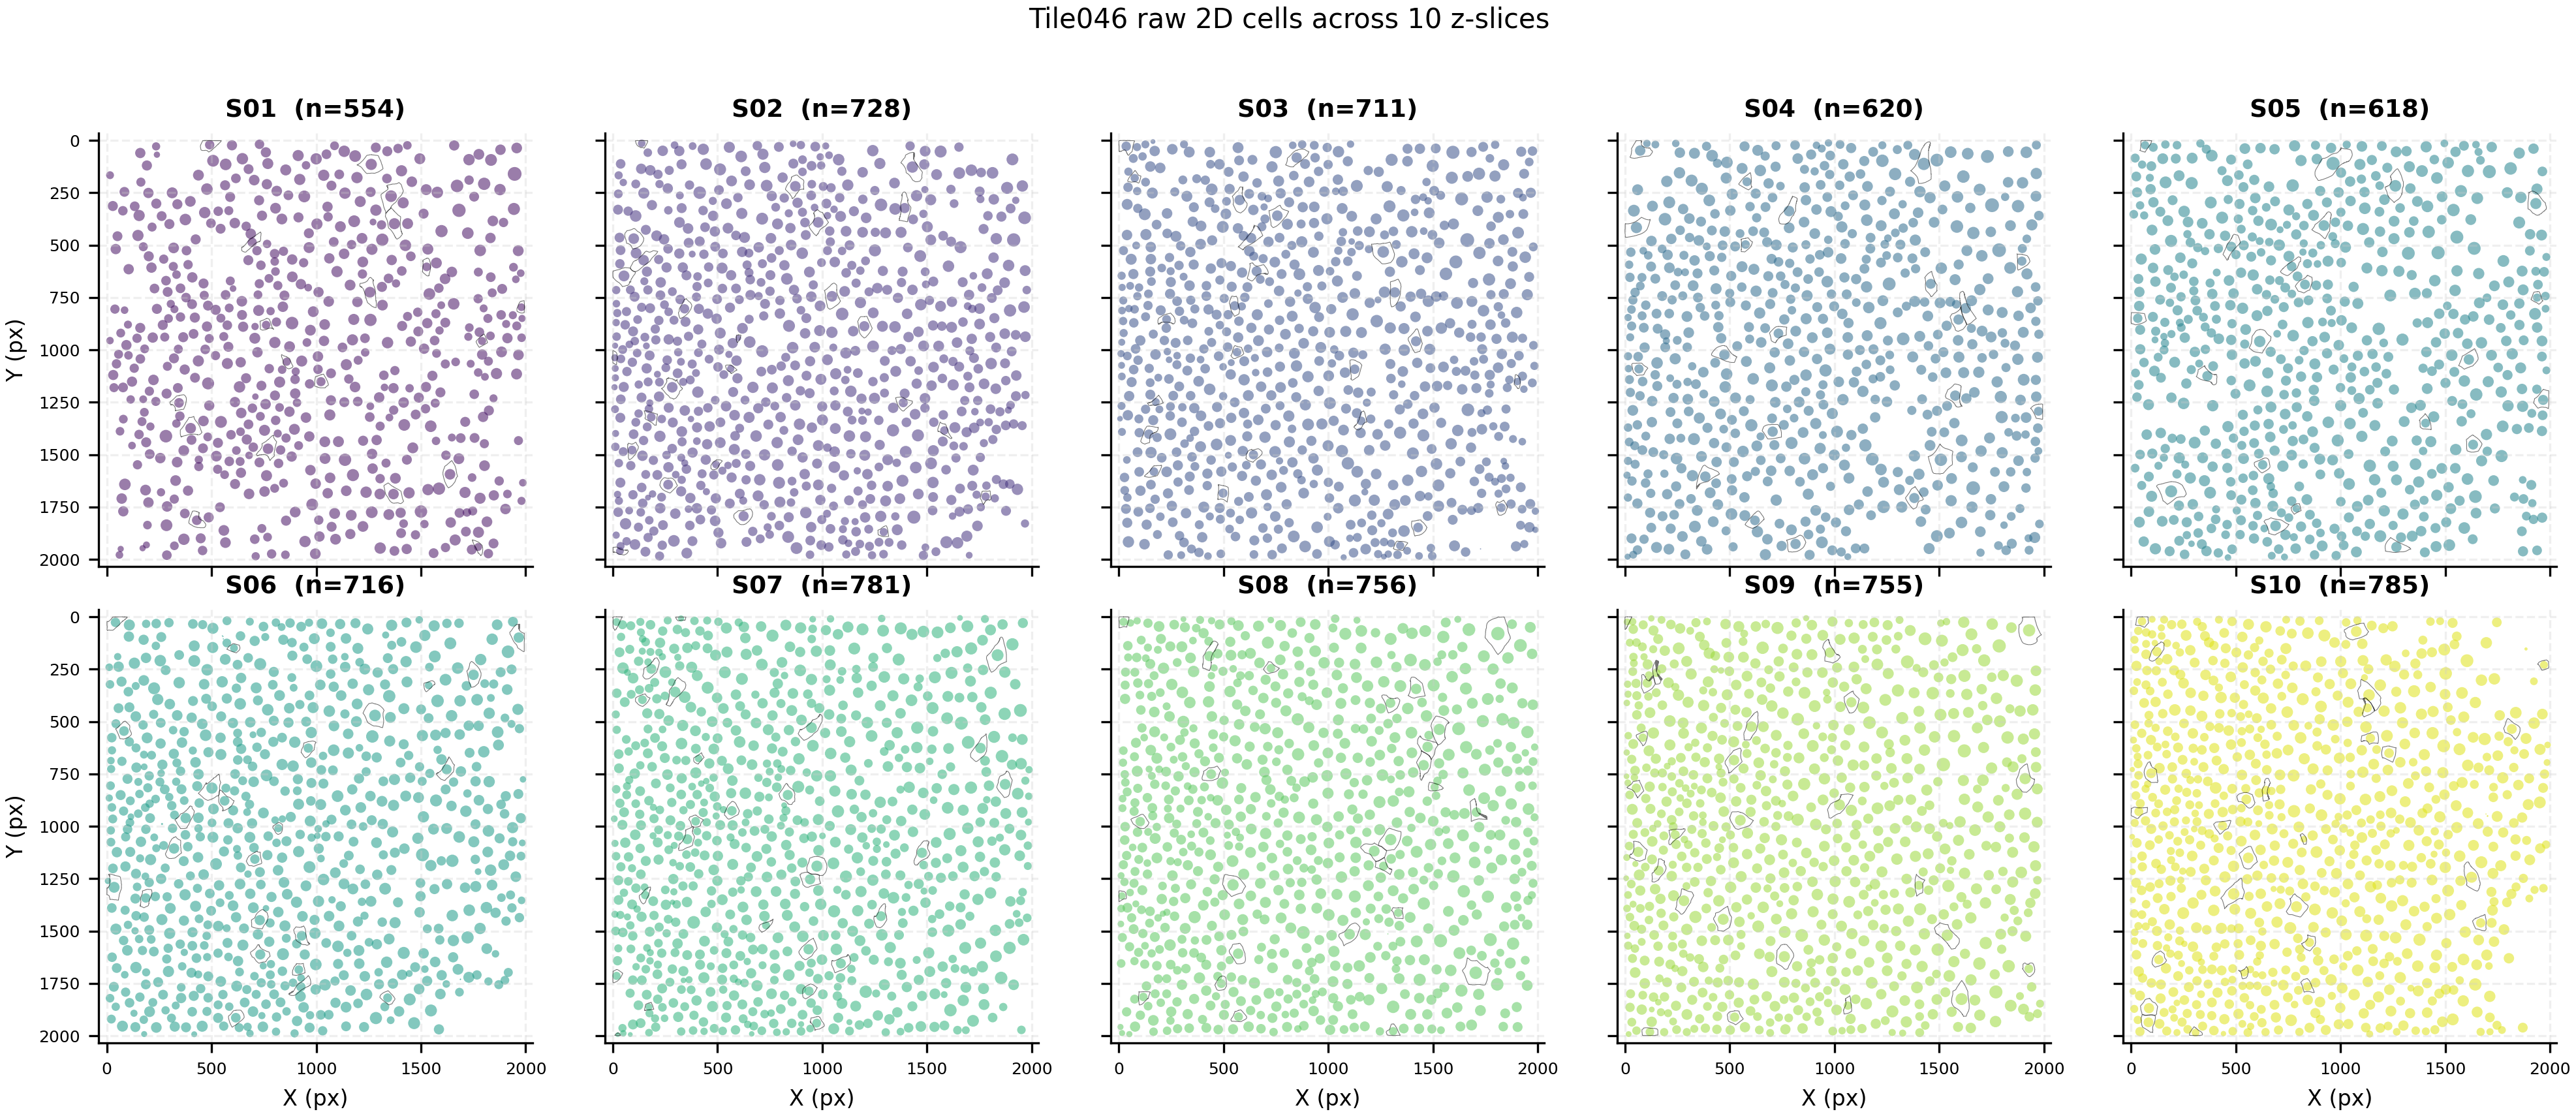

In [6]:
# Cache the global xy bounds; re-used by later track-overlay plots.
XY_BOUNDS = th.global_xy_bounds(cells_by_slice)

th.plot_raw_cells_grid(
    cells_by_slice,
    out_pdf=OUT_DIR / "01_raw_cells_2x5.pdf",
    title="Tile046 raw 2D cells across 10 z-slices",
)

## 4. Inspect candidate cells across layers (zoom-in)

Pick a small window around the slice-5 centroid centre and overlay the cells
from every Z layer that fall in that window. This is the kind of view the
matcher "sees" when it tries to associate a cell at z with a cell at z+1.

Cells are filled by slice-coloured polygons; tracks built by HiDTW will
roughly thread through these stacks.

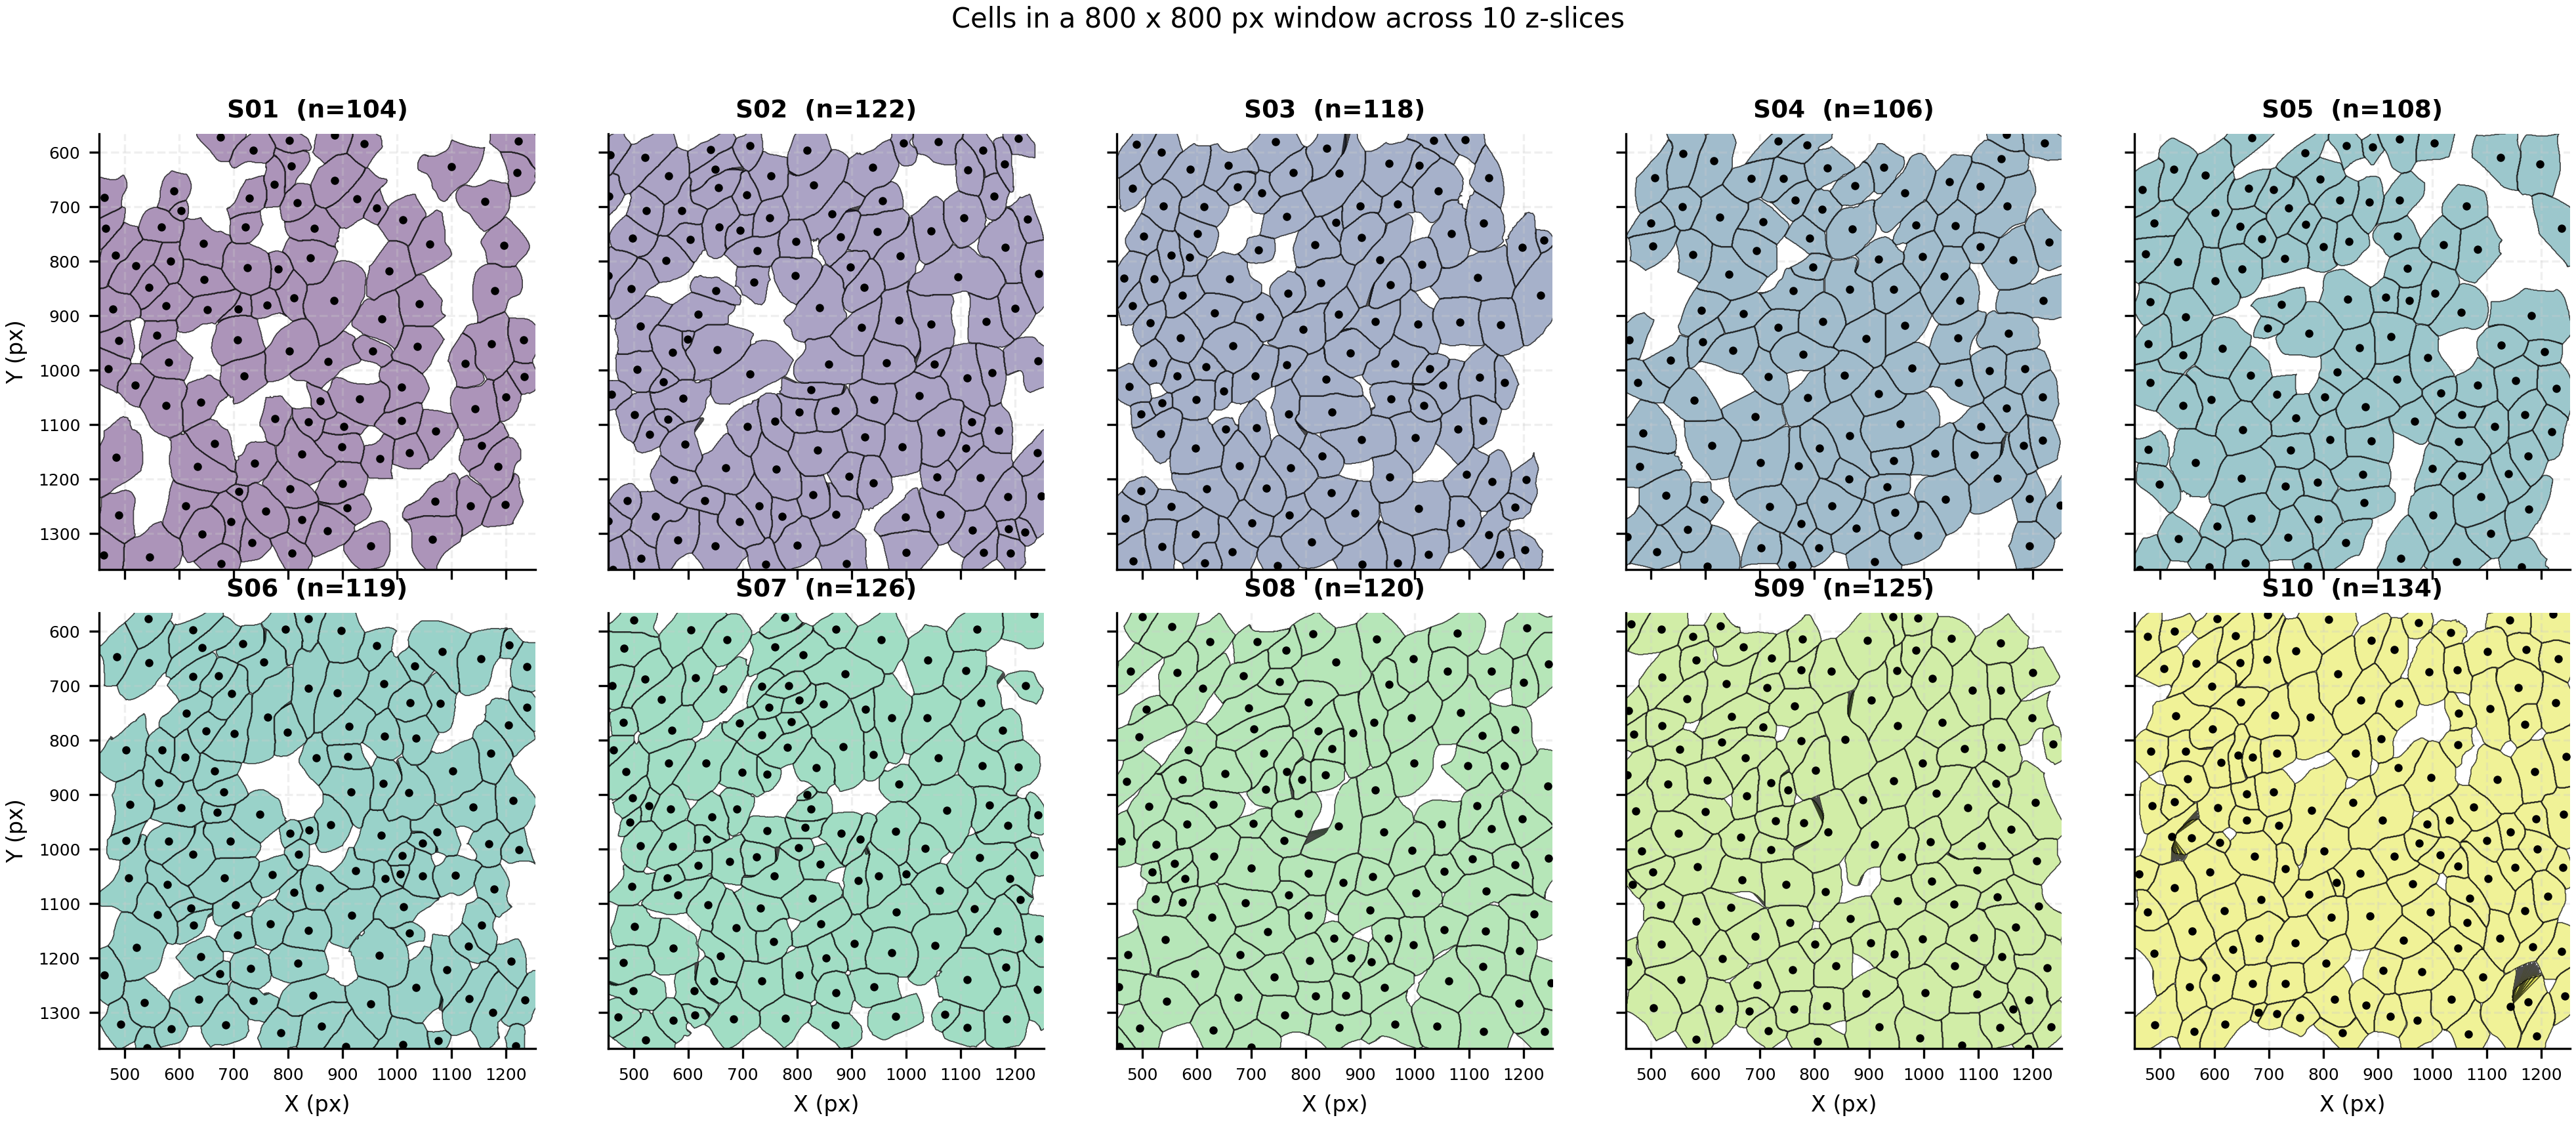

zoom centre: (853, 966)  half-width 400 px


In [7]:
cx_centre, cy_centre = th.plot_zoom_window(
    cells_by_slice,
    out_pdf=OUT_DIR / "02_zoom_window_S1toS10.pdf",
    title="Cells in a 800 x 800 px window across 10 z-slices",
    anchor_slice=5,
    half_width=400.0,
)
print(f"zoom centre: ({cx_centre:.0f}, {cy_centre:.0f})  half-width 400 px")

## 5. Calibrate global normalisation divisors

The matcher computes three raw distances (Soft-DTW between contours, Sinkhorn
OT between neighbour clusters, centroid distance). To make them comparable,
each is divided by a **dataset-specific divisor** so that the 75th percentile
of the empirical distance distribution maps to about 7.5 on a 0..10 scale.

The calibration samples ~50 candidate-pair distances on this dataset and
solves for the divisors. Results are cached on disk in
`divisor_cache_Tile046.json` so subsequent runs are instant.


In [8]:
cached = cr._load_divisor_cache(TILE_NAME)
if cached is not None:
    dtw_div = cached.get("dtw")
    ot_div = cached.get("ot")
    cent_div = cached.get("centroid")
else:
    if not GPU_AVAILABLE:
        raise RuntimeError(
            "Divisor calibration requires GPU (Soft-DTW + OT). "
            "Re-run on a CUDA-capable machine, or copy a previously-computed "
            "<TILE_NAME>_divisor_cache.json next to the notebook."
        )
    print("Calibrating divisors (~1-3 min)...")
    dtw_div, ot_div, cent_div = cr.calibrate_global_divisors(cells_by_slice, num_samples=50)

if dtw_div is not None:
    cr.DTW_NORM_DIVISOR = float(dtw_div)
if ot_div is not None:
    cr.OT_NORM_DIVISOR = float(ot_div)
if cent_div is not None:
    cr.CENTROID_NORM_DIVISOR = float(cent_div)

print(
    f"effective divisors: dtw={cr.DTW_NORM_DIVISOR:.0f}  "
    f"ot={cr.OT_NORM_DIVISOR:.0f}  centroid={cr.CENTROID_NORM_DIVISOR:.1f}"
)


Calibrating divisors (~1-3 min)...

Sample calibration for GLOBAL normalization parameters (for quality scoring)
Sampling 50 cell pairs from 10 layers...
Sampled 7 cell pairs (attempted 1000 times)
Computing sample metrics (DTW and OT)...


Progress:   0%|          | 0/7 [00:00<?, ?it/s]/root/autodl-tmp/HiDTW-3DVCM/soft_dtw_cuda.py:124: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at ../torch/csrc/tensor/python_tensor.cpp:78.)
  gamma = torch.cuda.FloatTensor([gamma])
Progress: 100%|██████████| 7/7 [00:00<00:00, 10.05it/s]


Sampling statistics:
   DTW:
      Samples: 7
      Median: 40956
      75th percentile: 129078
      GLOBAL_DIVISOR = 172104
   OT:
      Samples: 7
      Median: 25720
      75th percentile: 33188
      GLOBAL_DIVISOR = 44250
   Centroid: divisor fixed at 70.0 (not calibrated)

effective divisors: dtw=172104  ot=44250  centroid=70.0


## 6. Reconstruction with manual matching parameters

Four hyperparameters control matching:

- `DTW_WEIGHT`, `OT_WEIGHT`, `CENTROID_WEIGHT`: how much each comparator
  contributes to the final cost (must sum to 1).
- `RELATIVE_MARGIN_THRESHOLD`: the minimum gap between the top-1 and top-2
  candidate (relative to top-1's score) for a match to be accepted.

We start with sensible manual values; section 9 then searches the same space
with Bayesian optimisation.

**Multiple rounds:** each round walks every z-layer, but only cells **not yet**
assigned to a track are processed. The tqdm bar therefore shows how many cells
remain **unused** in that slice for that round.

The reconstruction cell uses `verbose=False` to hide detailed logs; tqdm bars
still appear so long runs stay visible. Use `verbose=True` for full console output.


In [9]:
if not GPU_AVAILABLE:
    raise RuntimeError(
        "Reconstruction requires CUDA. Skip to section 11 (expression aggregation) "
        "and use a pre-computed `cell_expression_3d/HiDTW_all_tiles_best_merged.csv` "
        "instead, or move to a GPU machine to continue."
    )

MANUAL_PARAMS = {
    "DTW_WEIGHT": 0.40,
    "OT_WEIGHT": 0.20,
    "CENTROID_WEIGHT": 0.40,
    "RELATIVE_MARGIN_THRESHOLD": 0.05,
}
for k, v in MANUAL_PARAMS.items():
    setattr(cr, k, v)

import multiprocessing as _mp
cr.NUM_PROCESSES = min(8, _mp.cpu_count())
print("manual parameters:", MANUAL_PARAMS)
print(f"NUM_PROCESSES = {cr.NUM_PROCESSES}")


manual parameters: {'DTW_WEIGHT': 0.4, 'OT_WEIGHT': 0.2, 'CENTROID_WEIGHT': 0.4, 'RELATIVE_MARGIN_THRESHOLD': 0.05}
NUM_PROCESSES = 8


In [10]:
t0 = time.time()
manual_tracks = cr.find_high_quality_tracks_layerwise(
    cells_by_slice,
    output_prefix=f"{TILE_NAME}_manual_",
    verbose=False,
)
print(f"\nmanual reconstruction: {len(manual_tracks)} tracks  ({time.time()-t0:.1f}s)")

Round 7 - slice 10: 100%|██████████| 233/233 [00:03<00:00, 70.78it/s]


manual reconstruction: 1131 tracks  (2880.2s)


## 7. Reconstruction visualisations

1. **Margin distribution** &mdash; per-track average matching margin (top1 - top2);
   higher means the matcher was more confident.
2. **3D ribbon (six panels)** &mdash; 2×3 subplots with contour ribbons between slices;
   tracks are split across panels so each view stays readable.


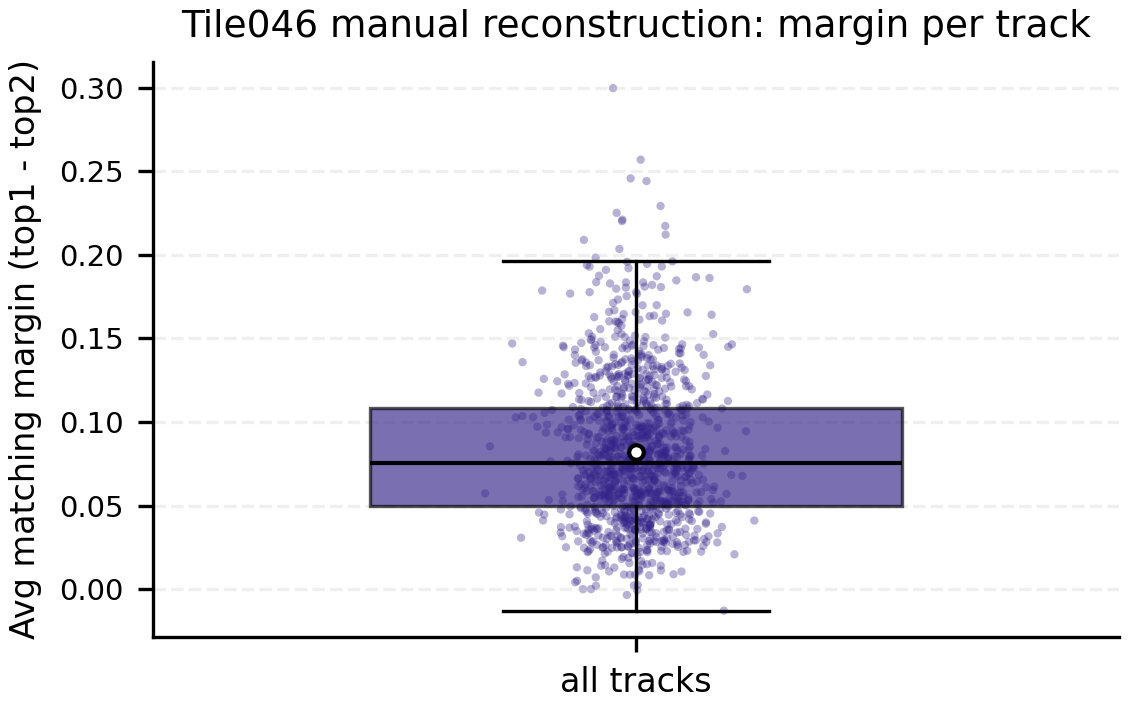

In [11]:
th.margin_distribution(
    manual_tracks,
    OUT_DIR / "04_margin_distribution_manual.pdf",
    "Tile046 manual reconstruction: margin per track",
)

The six panels split all eligible tracks (>=3 layers, n=1131) into six equally sized groups for readability; they are not six separate classes.


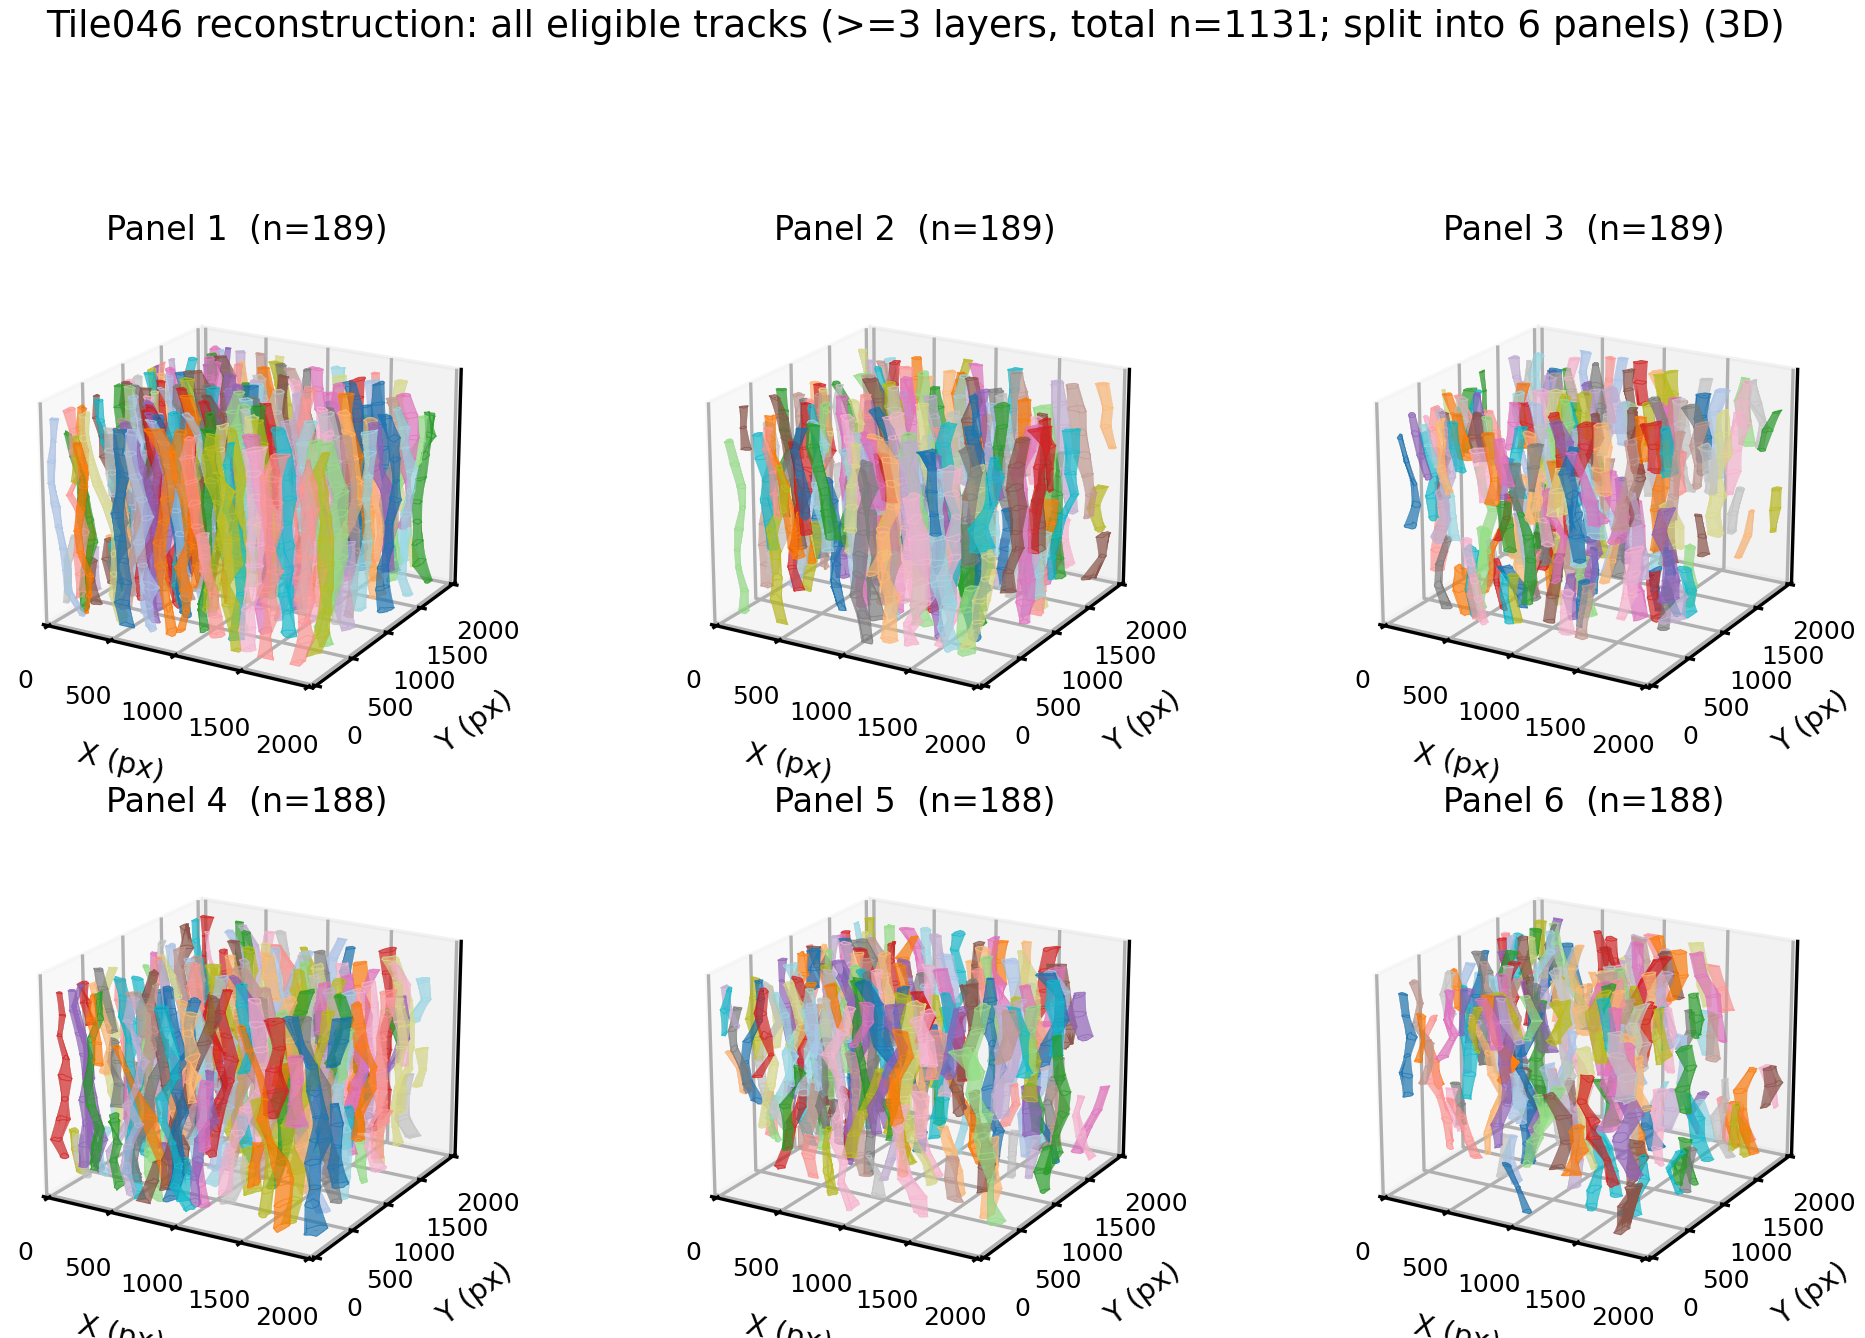

In [12]:
_manual_eligible_3d = [t for t in manual_tracks if t.get_layer_count() >= 3]
print(
    f"The six panels split all eligible tracks (>=3 layers, n={len(_manual_eligible_3d)}) "
    "into six equally sized groups for readability; they are not six separate classes."
)
th.sample_tracks_3d(
    manual_tracks,
    OUT_DIR / "06_sample_tracks_3d_manual.pdf",
    f"Tile046 reconstruction: all eligible tracks (>=3 layers, total n={len(_manual_eligible_3d)}; split into 6 panels) (3D)",
    n_show=None,
)

Drawing all eligible tracks (>=3 layers, n=1131) in one 3D panel. This view can be dense, but it shows the full reconstruction at once.


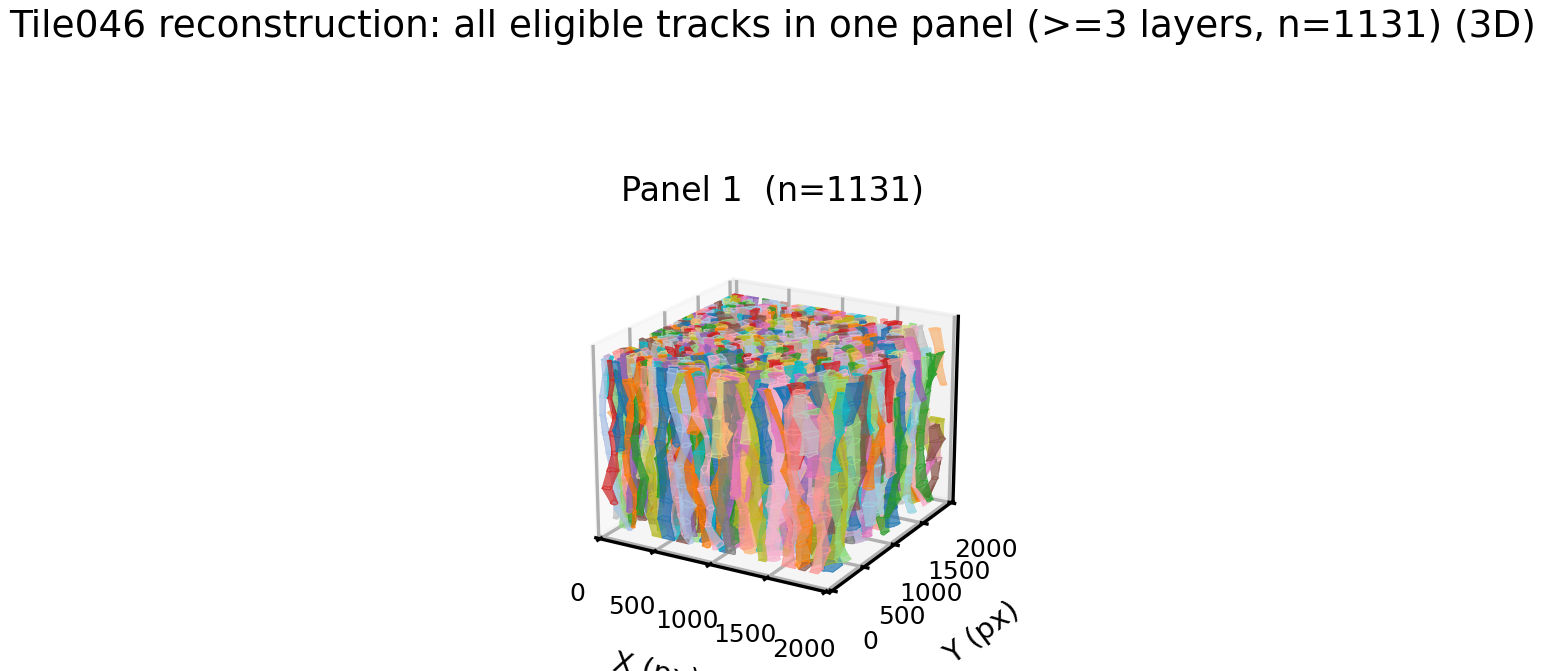

In [13]:
_manual_eligible_3d = [t for t in manual_tracks if t.get_layer_count() >= 3]
print(
    f"Drawing all eligible tracks (>=3 layers, n={len(_manual_eligible_3d)}) "
    "in one 3D panel. This view can be dense, but it shows the full reconstruction at once."
)
th.sample_tracks_3d(
    manual_tracks,
    OUT_DIR / "06b_sample_tracks_3d_manual_all_in_one.pdf",
    f"Tile046 reconstruction: all eligible tracks in one panel (>=3 layers, n={len(_manual_eligible_3d)}) (3D)",
    n_show=None,
    n_panels=1,
)

## 8. Quality evaluation

The pipeline scores a reconstruction with a single **global score** (0..100):

```
global_score = 0.4 * global_confidence + 0.4 * coverage + 0.2 * length
```

- `global_confidence` is the average decision-level margin (across **all**
  decisions, not just accepted matches), normalised to 0..100.
- `coverage` is the fraction of available 2D cells that ended up in some
  track.
- `length` rewards average track length (capped at 10 layers).

This is also the objective for Bayesian optimisation in section 9.

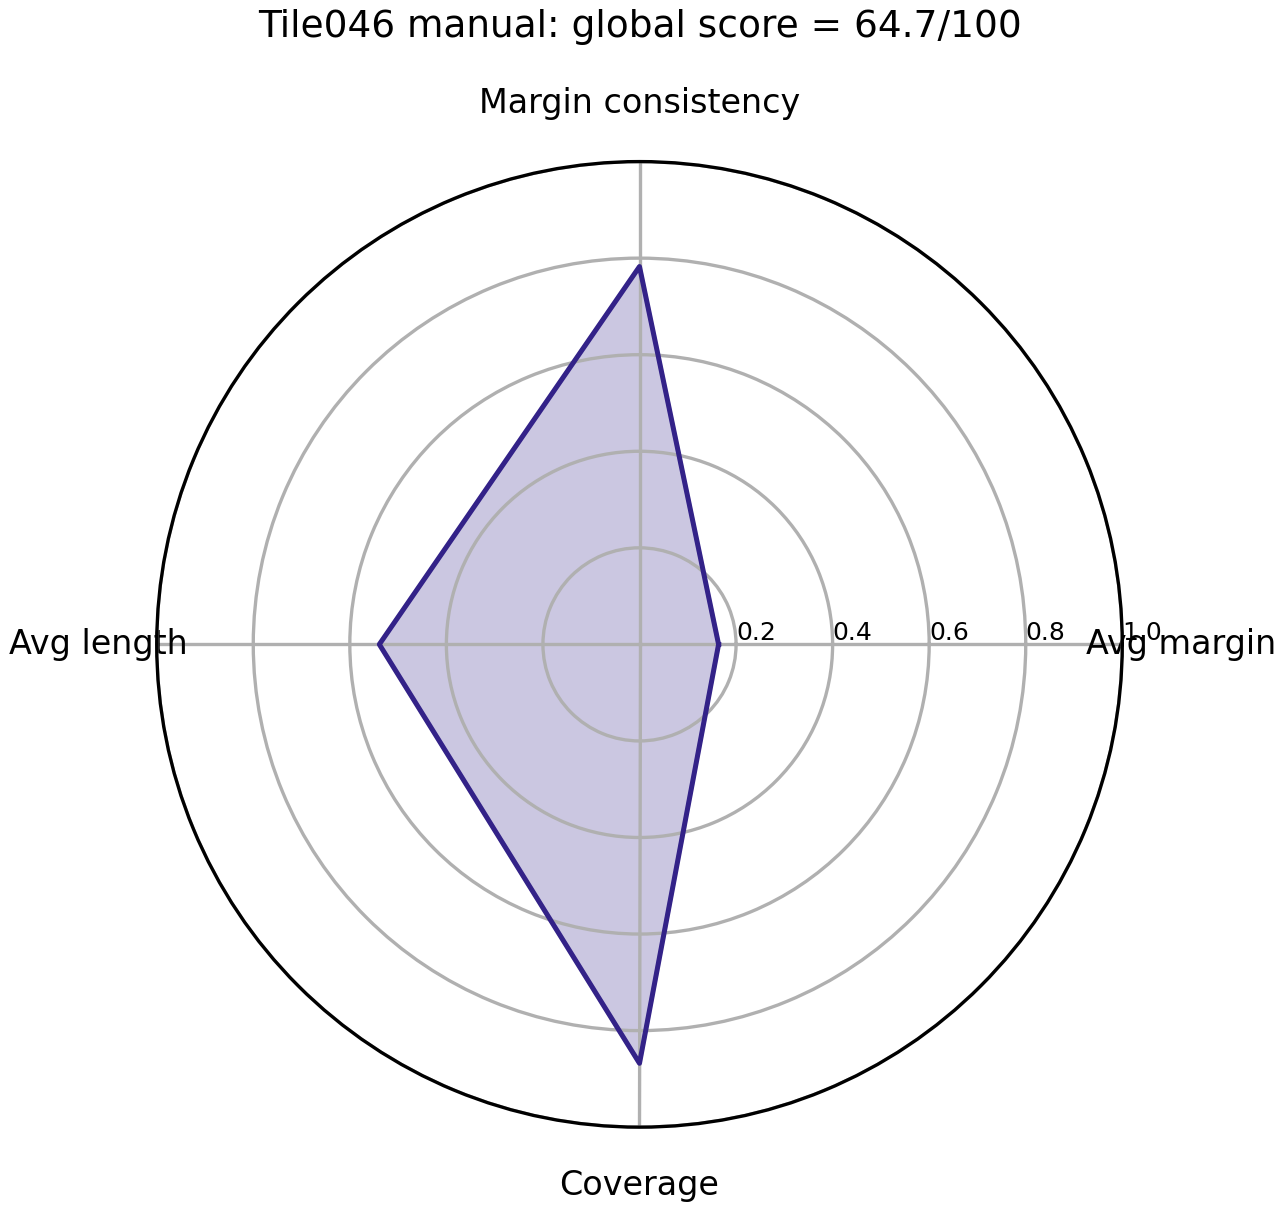

In [15]:
manual_metrics = cr.evaluate_all_tracks(manual_tracks, cells_by_slice)
with open(OUT_DIR / "manual_evaluation.json", "w") as f:
    json.dump(manual_metrics, f, indent=2)

th.evaluation_radar(
    manual_metrics,
    OUT_DIR / "07_evaluation_radar_manual.pdf",
    f"Tile046 manual: global score = {manual_metrics['global_score']:.1f}/100",
)

## 9. Bayesian optimisation (demo, n_calls=8)

[`bayes_opt_margin_v10.py`](hidtw_pipeline/bayes_opt_margin_v10.py) wraps the four-dimensional
search (RM, DTW, OT, CENT) with `skopt.gp_minimize`. Each evaluation rebuilds
the full reconstruction with the trial parameters, scores it, and feeds the
score back to the Gaussian-process surrogate.

Below we run a **short demo** (`n_calls=8`, `n_initial=3`) so the notebook
finishes in a sensible time. The CLI for the full run is given in the markdown immediately after the call.

We use `subprocess` (rather than importing `bayes_opt_margin_v10` in-process)
because the BO module spawns its own per-trial subprocess and shells out to a
modified copy of the reconstruction script.

**Dependency note:** the Python module `skopt` is provided by the pip package `scikit-optimize`. If the BO cell reports `ModuleNotFoundError: No module named 'skopt'`, install it in the same Jupyter kernel environment first:

```python
%pip install scikit-optimize
```

> **BO run:**
>
> ```bash
> python -m hidtw_pipeline.bayes_opt_margin_v10 --region Tile046 --gpu 0 --n-calls 30 --n-initial 8
> ```
>
> For multi-GPU parallel sweeps, run multiple instances with different `--region` / `--gpu` combinations.
>
> **Strong recommendation:** run the HiDTW BO pipeline from a terminal with `nohup`, rather than inside Jupyter:
>
> ```bash
> nohup python -m hidtw_pipeline.bayes_opt_margin_v10 --region Tile046 --gpu 0 --n-calls 30 --n-initial 8 > tutorial_outputs/Tile046/bayes_opt_production.log 2>&1 &
> ```


In [ ]:
import importlib.util

BO_N_CALLS = 8
BO_N_INITIAL = 3
BO_GPU = 0
log_path = OUT_DIR / "bayes_opt_log.txt"

if importlib.util.find_spec("skopt") is None:
    print("Missing dependency: run `%pip install scikit-optimize`, then rerun this cell.")
else:
    cmd = [
        sys.executable, "-m", "hidtw_pipeline.bayes_opt_margin_v10",
        "--region", TILE_NAME,
        "--gpu", str(BO_GPU),
        "--n-calls", str(BO_N_CALLS),
        "--n-initial", str(BO_N_INITIAL),
    ]
    print(f"Running BO demo ({BO_N_CALLS} calls). Log: {log_path}")
    with open(log_path, "w") as logf:
        proc = subprocess.run(
            cmd,
            cwd=str(WORK_DIR),
            stdout=logf,
            stderr=subprocess.STDOUT,
            text=True,
        )
    print(f"BO exit code: {proc.returncode}")
    print(f"Full log: {log_path}")


In [ ]:
BO_RESULT_DIR = WORK_DIR / f"bayes_opt_results_v9_{TILE_NAME}"
hist_csv = BO_RESULT_DIR / "optimization_history.csv"
hist_json = BO_RESULT_DIR / "optimization_history.json"

assert hist_csv.exists() and hist_json.exists(), (
    f"BO outputs not found in {BO_RESULT_DIR}; check the log: {log_path}"
)

bo_history = pd.read_csv(hist_csv)
with open(hist_json) as fh:
    bo_record = json.load(fh)
best_params = bo_record["best_params"]

print(f"BO trials: {len(bo_history)}")
print(f"best score:  {bo_record['best_score']:.2f} / 100")
print("best params:")
for k, v in best_params.items():
    print(f"   {k:28s} = {v:.4f}")
bo_history

In [ ]:
th.bo_convergence(
    bo_history,
    out_pdf=OUT_DIR / "08_bayes_opt_convergence.pdf",
    title=f"Bayesian optimisation convergence (Tile046, n={len(bo_history)})",
)

In [ ]:
th.bo_param_vs_score(
    bo_history,
    out_pdf=OUT_DIR / "09_bayes_opt_param_vs_score.pdf",
    title="BO trials: each parameter vs global score",
)

## 10. Re-run reconstruction with the best parameters

Apply the best-scoring point from BO and rebuild tracks. We then compare
manual vs BO on the same tile by overlaying their track-length distributions
and printing the global scores side-by-side.

In [ ]:
cr.DTW_WEIGHT = float(best_params["DTW_WEIGHT"])
cr.OT_WEIGHT = float(best_params["OT_WEIGHT"])
cr.CENTROID_WEIGHT = float(best_params["CENTROID_WEIGHT"])
cr.RELATIVE_MARGIN_THRESHOLD = float(best_params["RELATIVE_MARGIN_THRESHOLD"])
print("BO best parameters now active:")
for k in ["DTW_WEIGHT", "OT_WEIGHT", "CENTROID_WEIGHT", "RELATIVE_MARGIN_THRESHOLD"]:
    print(f"   cr.{k} = {getattr(cr, k):.4f}")

t0 = time.time()
best_tracks = cr.find_high_quality_tracks_layerwise(
    cells_by_slice,
    output_prefix=f"{TILE_NAME}_BO_",
    verbose=False,
)
print(f"BO reconstruction: {len(best_tracks)} tracks  ({time.time()-t0:.1f}s)")
best_metrics = cr.evaluate_all_tracks(best_tracks, cells_by_slice)
EXPR_STAGE_LABEL = "BO best reconstruction"
with open(OUT_DIR / "best_evaluation.json", "w") as fh:
    json.dump(best_metrics, fh, indent=2)

In [ ]:
th.compare_track_lengths(
    runs={"manual": manual_tracks, "BO best": best_tracks},
    out_pdf=OUT_DIR / "10_tracks_manual_vs_BO.pdf",
    title="Track length distribution: manual vs BO-optimised parameters",
)
print(f"manual: global_score = {manual_metrics['global_score']:.2f}")
print(f"BO   : global_score = {best_metrics['global_score']:.2f}")
print(f"delta = {best_metrics['global_score'] - manual_metrics['global_score']:+.2f}")

# Save the BO-optimised radar too.
th.evaluation_radar(
    best_metrics,
    OUT_DIR / "10b_evaluation_radar_BO.pdf",
    f"Tile046 BO best: global score = {best_metrics['global_score']:.1f}/100",
    color=PALETTE["accent"],
)

## 10b. Skip Bayesian optimisation — wire manual reconstruction

If you **do not run sections 9–10**, `best_tracks` / `best_metrics` are never
created. Execute the next cell so sections **11–12** use the **manual matching
parameters** reconstruction (`manual_tracks`, `manual_metrics` from §§6–8).

In [16]:
best_tracks = manual_tracks
best_metrics = manual_metrics
EXPR_STAGE_LABEL = "manual reconstruction"
print(EXPR_STAGE_LABEL, len(best_tracks), "tracks;", "global_score", best_metrics["global_score"])

manual reconstruction 1131 tracks; global_score 64.65605797795357


## 11. Aggregate per-track expression matrix

Now we build the **(cells x genes) UMI matrix** for the tracks in
`best_tracks` — after §10 these are **BO-optimised**; after §10b they are the
**manual** reconstruction — by re-aggregating the original per-2D-cell expression CSVs.

For each `Tile046` track we sum the `total_exp` of every member 2D cell
across all detected slices. The output schema mirrors the production pipeline
([build_3d_cell_expression.py](\u5176\u4ed6\u65b9\u6cd5\u5168\u5c40\u62fc\u63a5/build_3d_cell_expression.py)) so downstream R / Python tools that already consume
`HiDTW.csv.gz + HiDTW_meta.csv` can use the tutorial output without changes:

| file | purpose |
|---|---|
| `Tile046.csv.gz` | wide CSV: rows = `T046_TR000001` ... ; columns = `gene_<feature_index>` ; values = integer UMI |
| `Tile046_meta.csv` | per-track metadata (track length, UMI total, n_genes, ...) |
| `Tile046_all_tracks_summary.csv` | re-export of the matcher's track summary (margins, direction, member ids) |

In [17]:
expr_long = th.load_tile_expression_long(DEMO_EXPR_DIR, TILE_PREFIX)
print(f"loaded {len(expr_long):,} (z, cell, gene) records  "
      f"across {expr_long['z'].nunique()} z-slices")
cell_lut = th.build_cell_lookup(expr_long)
universe = th.gene_universe(expr_long)
print(f"unique 2D cells with expression: {len(cell_lut):,}")
print(f"gene universe size: {len(universe):,}")

loaded 5,113,487 (z, cell, gene) records  across 10 z-slices
unique 2D cells with expression: 7,013
gene universe size: 22,780


In [18]:
cell_ids, csr, meta = th.aggregate_tracks_to_csr(
    tracks=best_tracks, cell_lut=cell_lut, universe=universe,
    tile_prefix=TILE_PREFIX,
)
print(f"matrix shape (cells x genes): {csr.shape}")
print(f"non-zero entries (sparsity): {csr.nnz / (csr.shape[0] * csr.shape[1]):.4%}")
print(f"total UMI across matrix      : {csr.sum():,.0f}")

mat_path = OUT_DIR / f"{TILE_NAME}.csv.gz"
meta_path = OUT_DIR / f"{TILE_NAME}_meta.csv"
tracks_path = OUT_DIR / f"{TILE_NAME}_all_tracks_summary.csv"

th.write_matrix_csv_gz(mat_path, cell_ids, csr, universe)
meta.to_csv(meta_path, index=False)
th.write_tracks_summary_csv(best_tracks, tracks_path, tile_prefix=TILE_PREFIX)
print(f"\nwrote {mat_path}")
print(f"wrote {meta_path}")
print(f"wrote {tracks_path}")
meta.head()

matrix shape (cells x genes): (1131, 22780)
non-zero entries (sparsity): 10.5544%
total UMI across matrix      : 16,100,109

wrote /root/autodl-tmp/HiDTW-3DVCM/tutorial_outputs/Tile046/Tile046.csv.gz
wrote /root/autodl-tmp/HiDTW-3DVCM/tutorial_outputs/Tile046/Tile046_meta.csv
wrote /root/autodl-tmp/HiDTW-3DVCM/tutorial_outputs/Tile046/Tile046_all_tracks_summary.csv


,cell_id,tile,track_id,track_length,n_member_cells,n_member_cells_with_expr,total_umi,n_genes,start_slice,end_slice,avg_margin
0,T046_TR000001,046,1,3,3,3,9198.0,1890,1,3,0.256866
1,T046_TR000002,046,2,3,3,3,4560.0,1219,8,10,0.245683
2,T046_TR000003,046,3,3,3,3,4825.0,1091,2,4,0.229161
3,T046_TR000004,046,4,10,10,10,8730.0,1918,1,10,0.121943
4,T046_TR000005,046,5,10,10,10,28837.0,3759,1,10,0.119218


## 12. Sanity-check the expression matrix

Three independent checks:

1. **Total UMI per track** &mdash; should be roughly proportional to track length.
2. **distinct genes per track** &mdash; how many unique features each 3D cell
   carries, useful as a coverage signal.

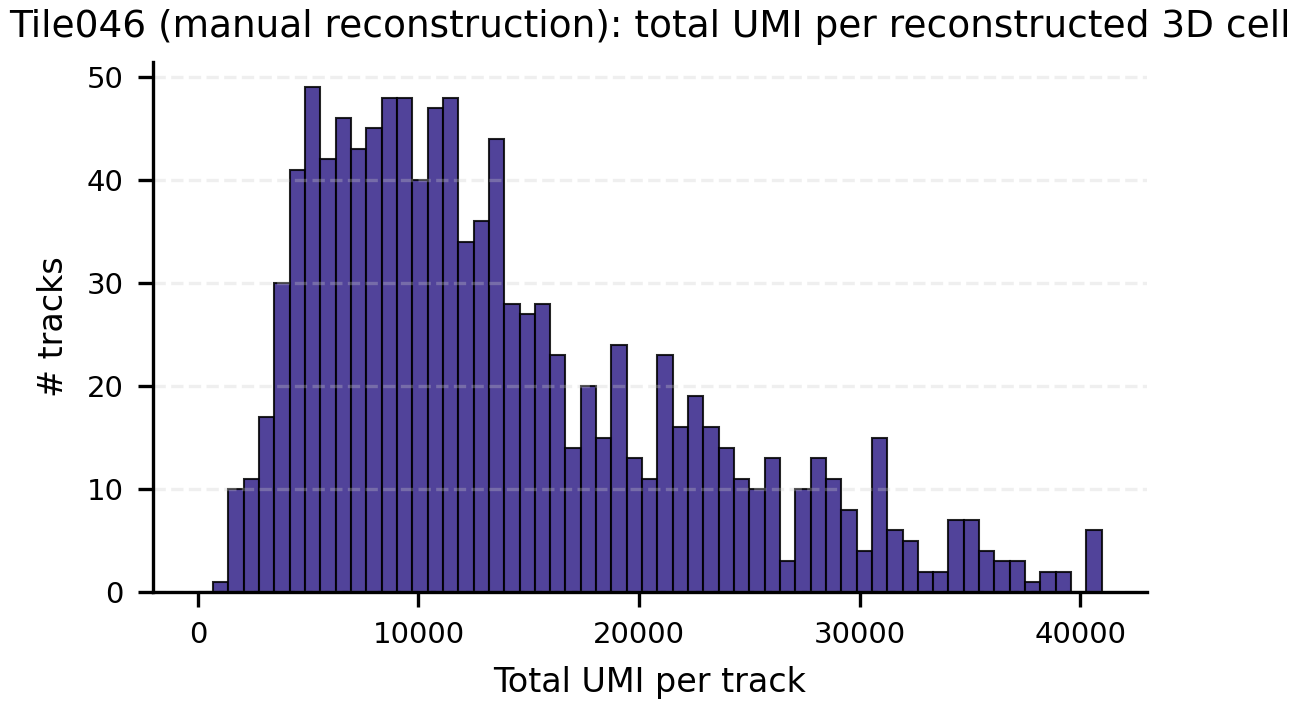

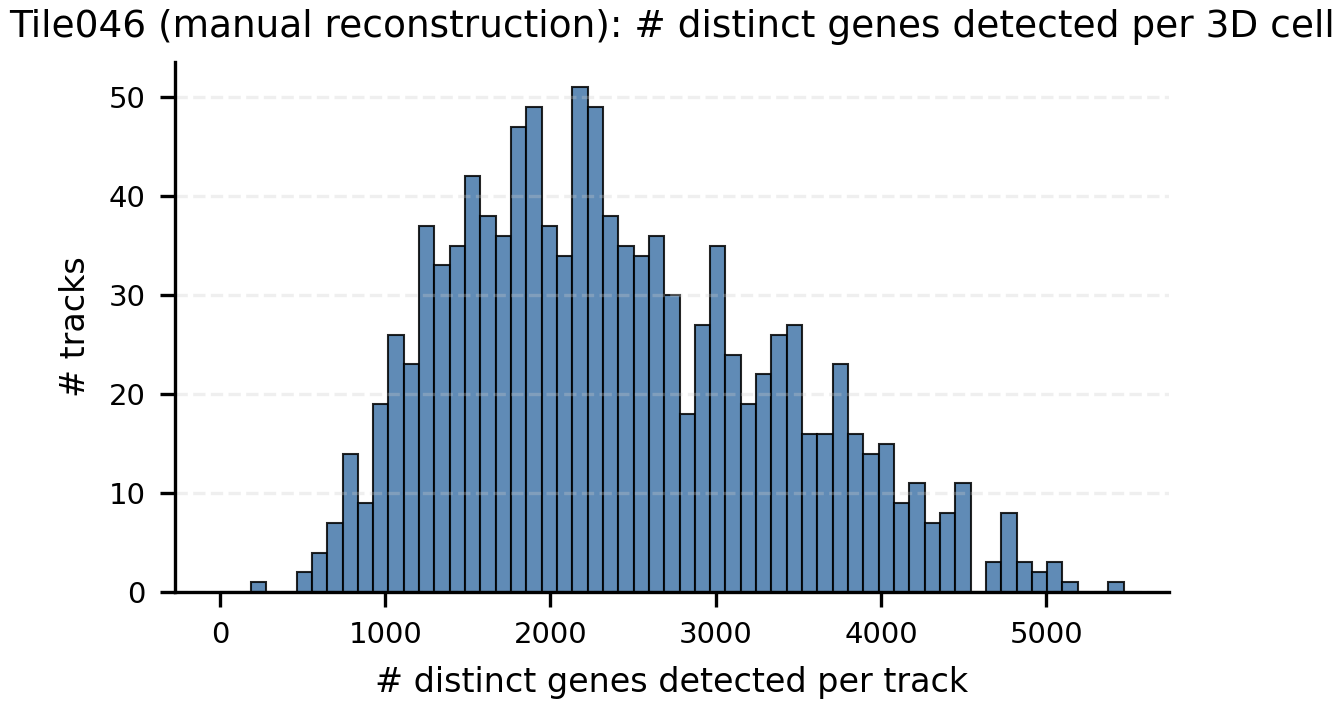

In [19]:
th.hist_total_umi_per_cell(
    meta, OUT_DIR / "11_umi_per_track.pdf",
    title=f"Tile046 ({EXPR_STAGE_LABEL}): total UMI per reconstructed 3D cell",
)
th.hist_n_genes_per_cell(
    meta, OUT_DIR / "12_genes_per_track.pdf",
    title=f"Tile046 ({EXPR_STAGE_LABEL}): # distinct genes detected per 3D cell",
)